# MedVision Smart — Second dataset : Kvasir-SEG
## Notebook 01_kvasir : exploration, nettoyage et découpage sans fuite

**Équipe :** Abderrahman Ghazouani · Hibatallah Hamrani · Mohammed Anas Latifi

---

### Pourquoi un second dataset ?

Le professeur demande de **refaire la même étude sur un second dataset** pour vérifier que nos conclusions ne dépendent pas de BUSI. L'énoncé propose **Kvasir-SEG** comme alternative ([datasets.simula.no/kvasir-seg](https://datasets.simula.no/kvasir-seg/)).

### Kvasir-SEG en bref

| | BUSI | **Kvasir-SEG** |
|---|---|---|
| Examen | Échographie du sein | **Coloscopie** (intérieur de l'intestin) |
| Images | Niveaux de gris | **Couleur (RGB)** |
| Ce qu'on segmente | Tumeurs | **Polypes** (excroissances pouvant devenir cancéreuses) |
| Nombre d'images | 780 | **1 000** |
| Classes | benign / malignant / normal | **une seule** : chaque image contient au moins un polype |
| Format | PNG | **JPEG** |

### Ce notebook applique **exactement la même démarche** que le notebook 01 de BUSI

1. Exploration (tailles, masques, taille des polypes)
2. Nettoyage : doublons exacts (MD5) et **quasi-doublons** (pHash + corrélation)
3. Découpage 70 / 15 / 15 **par groupe**, sans fuite
4. Sauvegarde de `splits_kvasir.csv`

**Deux adaptations** sont nécessaires :
- il n'y a pas de classes : la stratification se fait sur la **taille du polype** (petit / moyen / grand) ;
- les masques sont en JPEG : on les **binarise avec un seuil de 127** au lieu de `> 0`, pour que les éventuels artefacts de compression ne deviennent pas de faux pixels de polype.

---
## 0. Préparation

Mêmes bibliothèques et même graine (42) que pour BUSI. Le dataset doit être dézippé dans `data/Kvasir-SEG/`, avec les sous-dossiers `images/` et `masks/`.

In [1]:
import os, glob, hashlib, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import imagehash
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "data/Kvasir-SEG"
OUT_DIR = "outputs/kvasir"
os.makedirs(OUT_DIR, exist_ok=True)

SEUIL_MASQUE = 127   # binarisation des masques JPEG
TAILLES = ["petit", "moyen", "grand"]
COULEURS = {"petit": "#4C72B0", "moyen": "#DD8452", "grand": "#55A868"}
sns.set_theme(style="whitegrid")

print("Dossier trouvé :", os.path.isdir(DATA_DIR))

Dossier trouvé : True


---
## 1. Exploration

### 1.1 Inventaire

Chaque image `images/<nom>.jpg` a son masque `masks/<nom>.jpg`, avec **le même nom**. On vérifie que les deux listes correspondent exactement.

In [2]:
images = sorted(glob.glob(os.path.join(DATA_DIR, "images", "*.jpg")))
masques = sorted(glob.glob(os.path.join(DATA_DIR, "masks", "*.jpg")))
noms_img = [os.path.basename(p) for p in images]
noms_msk = [os.path.basename(p) for p in masques]

print("Images :", len(images), "| Masques :", len(masques))
print("Chaque image a son masque :", noms_img == noms_msk)

df = pd.DataFrame({
    "id": [n[:-4] for n in noms_img],
    "classe": "polype",
    "image_path": [p.replace("\\", "/") for p in images],
    "mask_paths": [p.replace("\\", "/") for p in masques],
    "nb_masques": 1,
})
df.head()

Images : 1000 | Masques : 1000
Chaque image a son masque : True


,id,classe,image_path,mask_paths,nb_masques
0,cju0qkwl35piu0993l0dewei2,polype,data/Kvasir-SEG/images/cju0qkwl35piu0993l0dewe...,data/Kvasir-SEG/masks/cju0qkwl35piu0993l0dewei...,1
1,cju0qoxqj9q6s0835b43399p4,polype,data/Kvasir-SEG/images/cju0qoxqj9q6s0835b43399...,data/Kvasir-SEG/masks/cju0qoxqj9q6s0835b43399p...,1
2,cju0qx73cjw570799j4n5cjze,polype,data/Kvasir-SEG/images/cju0qx73cjw570799j4n5cj...,data/Kvasir-SEG/masks/cju0qx73cjw570799j4n5cjz...,1
3,cju0roawvklrq0799vmjorwfv,polype,data/Kvasir-SEG/images/cju0roawvklrq0799vmjorw...,data/Kvasir-SEG/masks/cju0roawvklrq0799vmjorwf...,1
4,cju0rx1idathl0835detmsp84,polype,data/Kvasir-SEG/images/cju0rx1idathl0835detmsp...,data/Kvasir-SEG/masks/cju0rx1idathl0835detmsp8...,1


### 1.2 Les masques JPEG : faut-il un seuil ?

Un masque devrait contenir seulement 0 (fond) et 255 (polype). Mais la compression JPEG peut créer des **valeurs intermédiaires** sur les bords. On compte combien de pixels ne valent ni 0 ni 255, et on compare deux façons de binariser : `> 0` et `> 127`.

In [3]:
intermediaires, diff_seuils = [], []
for p in masques:
    m = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    intermediaires.append(((m > 0) & (m < 255)).mean())
    diff_seuils.append(((m > 0) != (m > SEUIL_MASQUE)).mean())

print(f"Part moyenne de pixels ni 0 ni 255 : {np.mean(intermediaires) * 100:.3f} %")
print(f"Masques contenant de tels pixels : {np.sum(np.array(intermediaires) > 0)} / {len(masques)}")
print(f"Pixels classés différemment par '> 0' et '> 127' : {np.mean(diff_seuils) * 100:.3f} %")

Part moyenne de pixels ni 0 ni 255 : 0.767 %
Masques contenant de tels pixels : 1000 / 1000
Pixels classés différemment par '> 0' et '> 127' : 0.391 %


**Décision :** on binarise tous les masques avec **`> 127`**. C'est la règle sûre pour un format compressé : un pixel n'est « polype » que s'il est plus proche du blanc que du noir. Pour BUSI (PNG), `> 0` et `> 127` sont équivalents.

In [4]:
def lire_image(chemin):
    # Image couleur en RGB (OpenCV lit en BGR par défaut).
    return cv2.cvtColor(cv2.imread(chemin), cv2.COLOR_BGR2RGB)


def lire_masque(chemin):
    # Masque binaire 0/1, seuil 127 (masques JPEG).
    return (cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) > SEUIL_MASQUE).astype(np.uint8)

### 1.3 Analyse de chaque image

Comme pour BUSI, on calcule pour chaque image : sa taille, la part de l'image occupée par le polype (`ratio_tumeur`, même nom que pour BUSI pour garder un format commun), le nombre de polypes (zones séparées du masque) et une empreinte MD5.

In [5]:
infos = []
for _, l in tqdm(df.iterrows(), total=len(df), desc="Analyse des images"):
    img = cv2.imread(l["image_path"])
    m = lire_masque(l["mask_paths"])
    infos.append({
        "hauteur": img.shape[0], "largeur": img.shape[1],
        "taille_ok": img.shape[:2] == m.shape,
        "ratio_tumeur": float(m.mean()),
        "nb_lesions": cv2.connectedComponents(m)[0] - 1,
        "hash": hashlib.md5(str(img.shape).encode() + img.tobytes()).hexdigest(),
    })
df = pd.concat([df, pd.DataFrame(infos)], axis=1)

print("Masques de la même taille que leur image :", df["taille_ok"].all())
print("Masques vides :", (df["ratio_tumeur"] == 0).sum())
display(df["nb_lesions"].value_counts().sort_index().rename_axis("polypes par image").rename("nb_images").to_frame())

Analyse des images:   0%|          | 0/1000 [00:00<?, ?it/s]

Analyse des images:   2%|▏         | 18/1000 [00:00<00:05, 179.84it/s]

Analyse des images:   4%|▍         | 44/1000 [00:00<00:04, 222.36it/s]

Analyse des images:   7%|▋         | 69/1000 [00:00<00:03, 233.34it/s]

Analyse des images:   9%|▉         | 93/1000 [00:00<00:03, 230.10it/s]

Analyse des images:  12%|█▏        | 117/1000 [00:00<00:03, 220.98it/s]

... (35 outputs left out)

Analyse des images:  98%|█████████▊| 984/1000 [00:04<00:00, 190.47it/s]

Analyse des images: 100%|██████████| 1000/1000 [00:04<00:00, 217.62it/s]

Masques de la même taille que leur image : True
Masques vides : 0


,nb_images
polypes par image,
1,820
2,163
3,14
4,2
10,1


### 1.4 Taille des images

,hauteur,largeur
count,1000.0,1000.0
mean,545.0,625.0
std,91.0,130.0
min,352.0,332.0
25%,529.0,592.0
50%,530.0,621.0
75%,531.0,622.0
max,1072.0,1920.0


Nombre de tailles différentes : 333


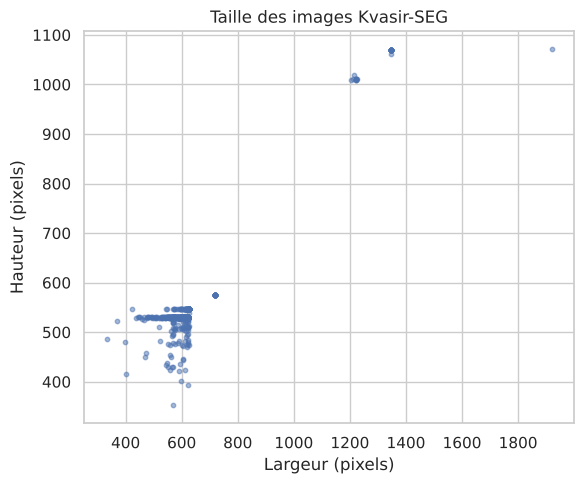

In [6]:
display(df[["hauteur", "largeur"]].describe().round(0))
print("Nombre de tailles différentes :", df.groupby(["hauteur", "largeur"]).ngroups)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df["largeur"], df["hauteur"], s=10, alpha=0.5, color="#4C72B0")
ax.set_xlabel("Largeur (pixels)")
ax.set_ylabel("Hauteur (pixels)")
ax.set_title("Taille des images Kvasir-SEG")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/tailles_images.png", dpi=150)
plt.show()

**Interprétation :** les tailles varient beaucoup (de quelques centaines à près de 2 000 pixels de large). Comme pour BUSI, toutes les images seront **redimensionnées en 256 × 256** avant l'entraînement.

### 1.5 Taille des polypes et catégories

Kvasir-SEG n'a pas de classes. Pour **stratifier** le découpage et pour présenter les résultats **par catégorie de lésion** (remarque du professeur), on répartit les images en **trois catégories de taille de même effectif** (terciles de `ratio_tumeur`) : **petit, moyen, grand**.

Bornes des catégories (% de l'image occupée par le polype) :


,min,max,count
taille_cat,,,
petit,0.47,7.70,334
moyen,7.70,16.69,333
grand,16.82,81.18,333


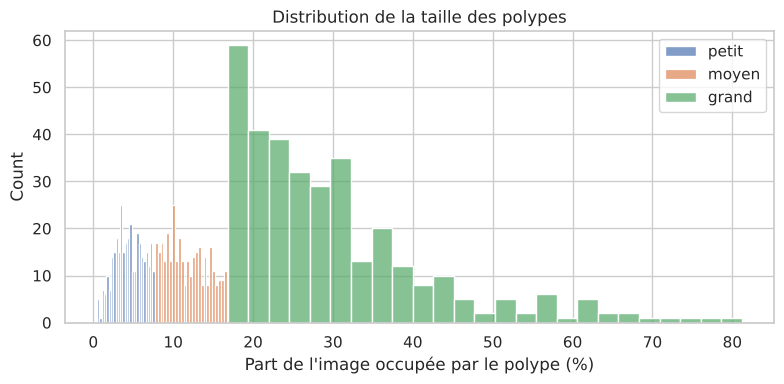

In [7]:
df["taille_cat"] = pd.qcut(df["ratio_tumeur"], 3, labels=TAILLES).astype(str)
bornes = (df.groupby("taille_cat")["ratio_tumeur"].agg(["min", "max", "count"])
          .reindex(TAILLES))
bornes[["min", "max"]] = (bornes[["min", "max"]] * 100).round(2)
print("Bornes des catégories (% de l'image occupée par le polype) :")
display(bornes)

fig, ax = plt.subplots(figsize=(8, 4))
for t in TAILLES:
    sns.histplot(df.loc[df["taille_cat"] == t, "ratio_tumeur"] * 100, bins=25, ax=ax,
                 color=COULEURS[t], label=t, alpha=0.7)
ax.set_xlabel("Part de l'image occupée par le polype (%)")
ax.set_title("Distribution de la taille des polypes")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/taille_polypes.png", dpi=150)
plt.show()

### 1.6 Exemples

Un exemple par catégorie de taille : l'image, son masque, et le masque superposé en couleur.

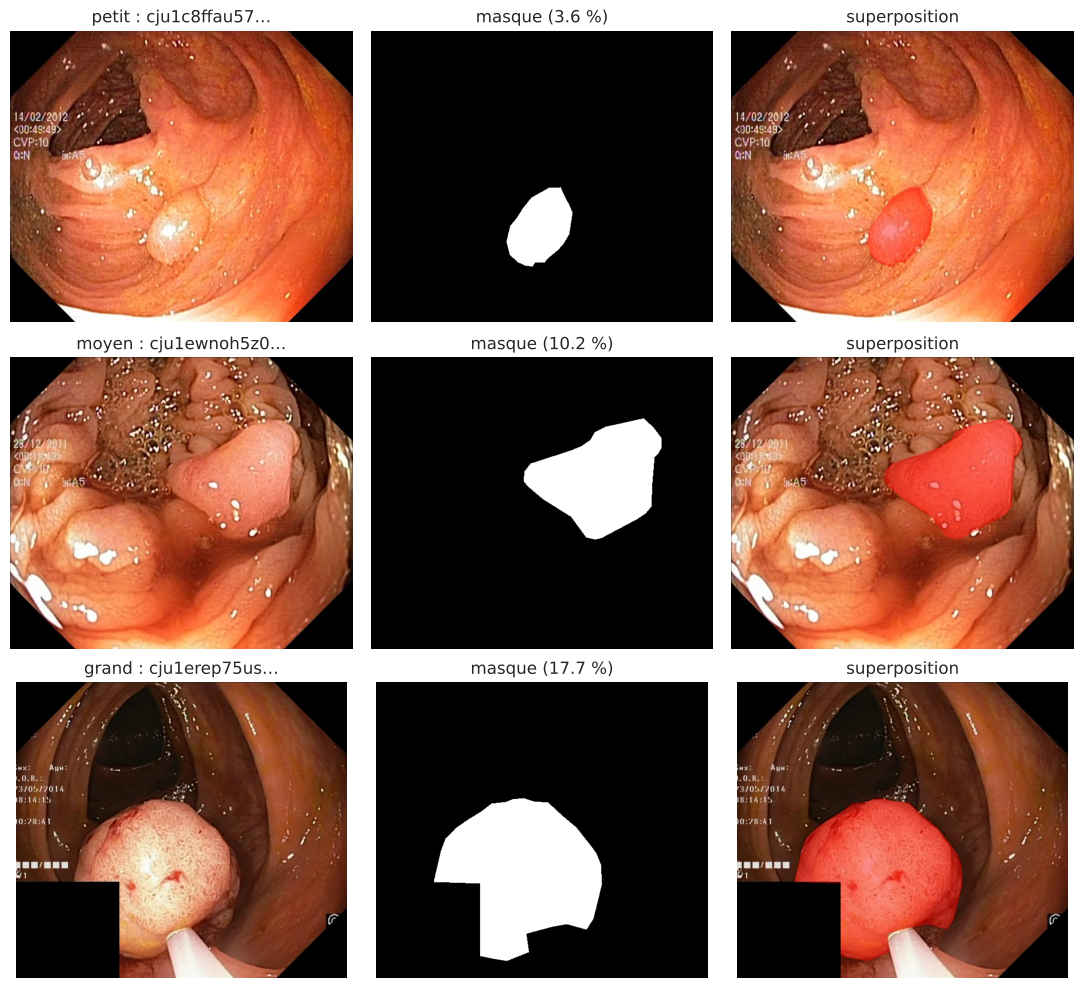

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for i, t in enumerate(TAILLES):
    l = df[df["taille_cat"] == t].sample(1, random_state=SEED).iloc[0]
    img, m = lire_image(l["image_path"]), lire_masque(l["mask_paths"])
    axes[i, 0].imshow(img); axes[i, 0].set_title(f"{t} : {l['id'][:12]}…")
    axes[i, 1].imshow(m, cmap="gray"); axes[i, 1].set_title(f"masque ({l['ratio_tumeur'] * 100:.1f} %)")
    axes[i, 2].imshow(img); axes[i, 2].imshow(np.ma.masked_where(m == 0, m), cmap="autumn", alpha=0.45)
    axes[i, 2].set_title("superposition")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/exemples_par_taille.png", dpi=150)
plt.show()

---
## 2. Nettoyage

### 2.1 Doublons exacts (MD5)

In [9]:
doublons = df[df.duplicated("hash", keep=False)].sort_values("hash")
print("Images faisant partie d'un doublon exact :", len(doublons))
if len(doublons):
    display(doublons[["id", "hash"]])
df_clean = df.drop_duplicates(subset="hash", keep="first").reset_index(drop=True)
print("Images après suppression des doublons exacts :", len(df_clean))

Images faisant partie d'un doublon exact : 0
Images après suppression des doublons exacts : 1000


### 2.2 Quasi-doublons : premier essai avec la méthode de BUSI

On applique d'abord **exactement la méthode de BUSI** : pHash et corrélation calculés sur l'image entière en niveaux de gris, distance ≤ 12 et corrélation ≥ 0,85, puis regroupement par union-find.

In [10]:
def centre(g, marge):
    # Garde la partie centrale de l'image (marge = part retirée de chaque côté).
    h, w = g.shape
    return g[int(h * marge):int(h * (1 - marge)), int(w * marge):int(w * (1 - marge))]


def empreintes(marge):
    bits, vignettes = [], []
    for chemin in tqdm(df_clean["image_path"], desc=f"Empreintes (marge {marge})"):
        g = centre(cv2.imread(chemin, cv2.IMREAD_GRAYSCALE), marge)
        bits.append(imagehash.phash(Image.fromarray(g)).hash.flatten())
        vignettes.append(cv2.resize(g, (128, 128), interpolation=cv2.INTER_AREA).astype(np.float32).ravel())
    bits, vignettes = np.array(bits, dtype=bool), np.array(vignettes)
    distance = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)
    z = (vignettes - vignettes.mean(1, keepdims=True)) / (vignettes.std(1, keepdims=True) + 1e-8)
    return distance, (z @ z.T) / z.shape[1]


def grouper(distance, correlation, dmax, cmin):
    # Union-find sur les paires qui passent les deux seuils ; renvoie (paires, numéro de groupe par image).
    i, j = np.where(np.triu((distance <= dmax) & (correlation >= cmin), k=1))
    parent = list(range(len(distance)))
    def racine(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for a, b in zip(i, j):
        parent[racine(a)] = racine(b)
    return list(zip(i, j)), pd.factorize(np.array([racine(k) for k in range(len(distance))]))[0]


def resume(groupes):
    tailles = pd.Series(groupes).value_counts()
    return {"groupes": int((tailles > 1).sum()), "images": int(tailles[tailles > 1].sum()), "plus grand": int(tailles.max())}


dist_full, corr_full = empreintes(marge=0.0)
paires_full, groupes_full = grouper(dist_full, corr_full, 12, 0.85)
print("Méthode BUSI, image entière :", len(paires_full), "paires ->", resume(groupes_full))

Empreintes (marge 0.0):   0%|          | 0/1000 [00:00<?, ?it/s]

Empreintes (marge 0.0):   3%|▎         | 26/1000 [00:00<00:03, 254.13it/s]

Empreintes (marge 0.0):   6%|▌         | 56/1000 [00:00<00:03, 279.87it/s]

Empreintes (marge 0.0):   8%|▊         | 85/1000 [00:00<00:03, 282.79it/s]

Empreintes (marge 0.0):  12%|█▏        | 118/1000 [00:00<00:02, 299.33it/s]

Empreintes (marge 0.0):  15%|█▍        | 149/1000 [00:00<00:02, 302.04it/s]

... (25 outputs left out)

Empreintes (marge 0.0):  94%|█████████▍| 938/1000 [00:03<00:00, 296.95it/s]

Empreintes (marge 0.0):  97%|█████████▋| 970/1000 [00:03<00:00, 303.55it/s]

Empreintes (marge 0.0): 100%|██████████| 1000/1000 [00:03<00:00, 277.67it/s]

Méthode BUSI, image entière : 213 paires -> {'groupes': 18, 'images': 163, 'plus grand': 110}


**Problème :** cette méthode produit un **groupe géant** de plus de 100 images. Affichons-en quelques-unes.

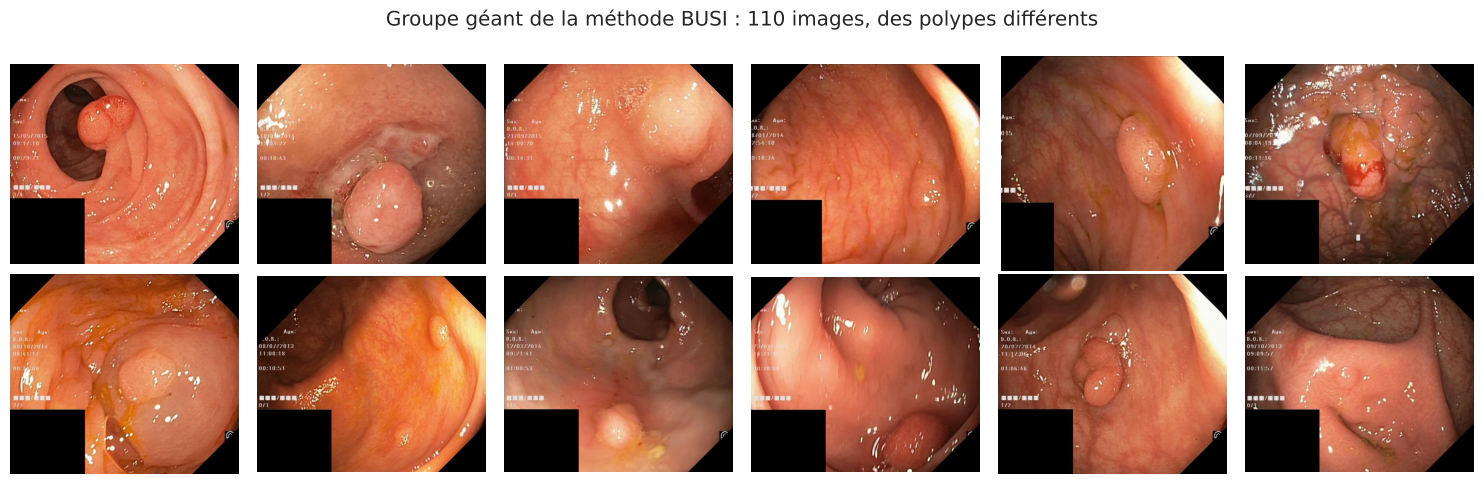

In [11]:
geant = pd.Series(groupes_full).value_counts().index[0]
idx = np.where(groupes_full == geant)[0][:12]
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, k in zip(axes.ravel(), idx):
    ax.imshow(lire_image(df_clean.loc[k, "image_path"]))
    ax.axis("off")
fig.suptitle(f"Groupe géant de la méthode BUSI : {(groupes_full == geant).sum()} images, des polypes différents")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/faux_groupe_geant.png", dpi=120)
plt.show()

Ce sont des **polypes différents**. Toutes les images Kvasir-SEG partagent le **même cadre** : bords noirs octogonaux, encart noir en bas à gauche, texte de l'appareil. Ce cadre commun suffit à rendre deux images « proches » pour le pHash et la corrélation, puis l'union-find **enchaîne** les paires (A ressemble à B, B à C…) jusqu'à former un groupe géant.

Ce faux groupe aurait des conséquences graves : placé entier dans une seule partition, il déséquilibre complètement le découpage (le test passe à 24 % des images).

### 2.3 Méthode corrigée : le centre de l'image

On recalcule les empreintes sur la **partie centrale** de l'image (20 % retirés de chaque côté), là où se trouve le contenu médical, sans le cadre. On regarde ensuite **toutes les paires candidates** avec les seuils de BUSI.

Empreintes (marge 0.2):   0%|          | 0/1000 [00:00<?, ?it/s]

Empreintes (marge 0.2):   5%|▍         | 46/1000 [00:00<00:02, 459.12it/s]

Empreintes (marge 0.2):  10%|▉         | 97/1000 [00:00<00:01, 485.38it/s]

Empreintes (marge 0.2):  15%|█▍        | 149/1000 [00:00<00:01, 499.17it/s]

Empreintes (marge 0.2):  20%|█▉        | 199/1000 [00:00<00:01, 472.43it/s]

Empreintes (marge 0.2):  25%|██▍       | 249/1000 [00:00<00:01, 473.61it/s]

... (13 outputs left out)

Empreintes (marge 0.2):  95%|█████████▍| 949/1000 [00:02<00:00, 486.10it/s]

Empreintes (marge 0.2): 100%|█████████▉| 998/1000 [00:02<00:00, 429.58it/s]

Empreintes (marge 0.2): 100%|██████████| 1000/1000 [00:02<00:00, 459.53it/s]

Centre de l'image, seuils BUSI : 13 paires candidates


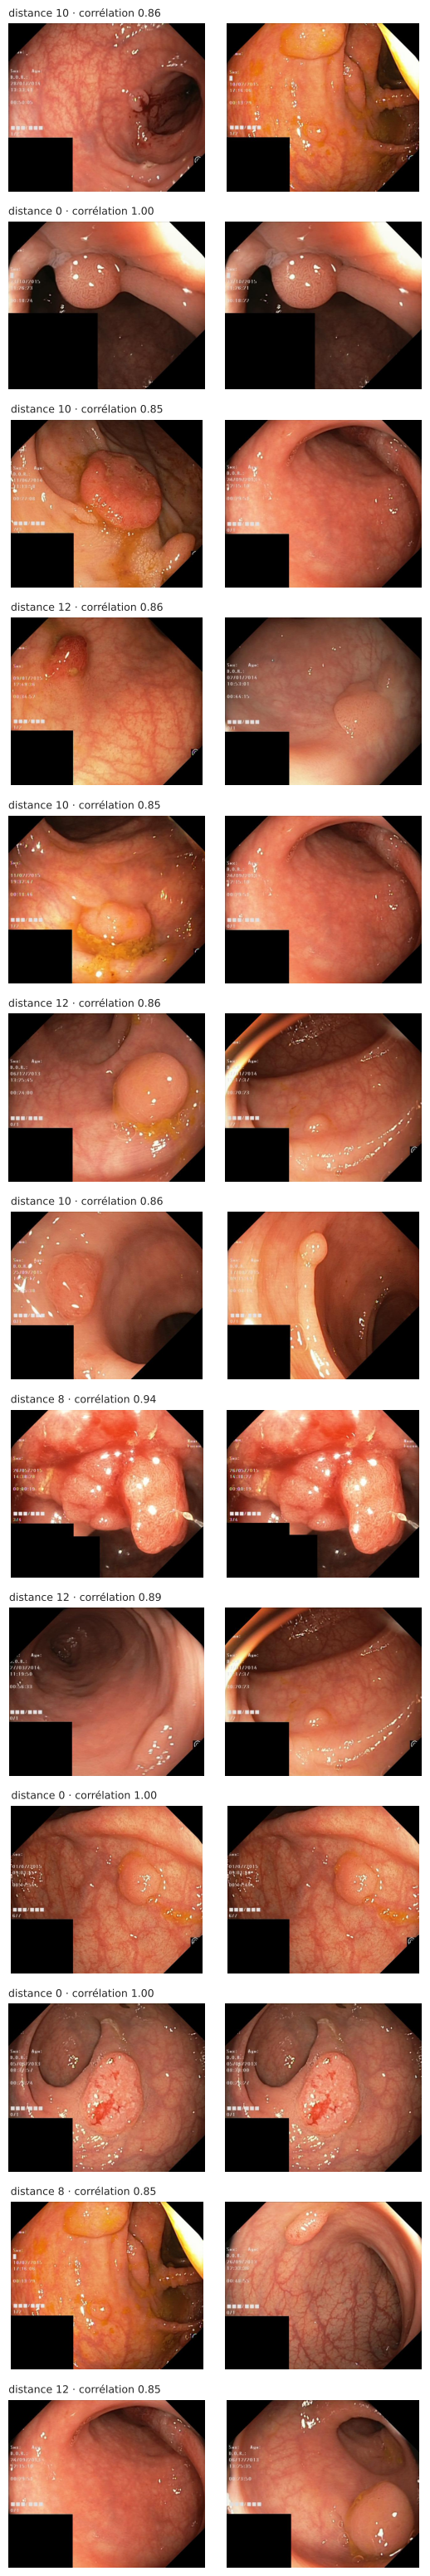

In [12]:
dist_c, corr_c = empreintes(marge=0.2)
paires_c, _ = grouper(dist_c, corr_c, 12, 0.85)
print("Centre de l'image, seuils BUSI :", len(paires_c), "paires candidates")

fig, axes = plt.subplots(len(paires_c), 2, figsize=(5.5, 2.4 * len(paires_c)))
axes = np.atleast_2d(axes)
for k, (a, b) in enumerate(paires_c):
    for ax, p in zip(axes[k], [a, b]):
        ax.imshow(lire_image(df_clean.loc[p, "image_path"]))
        ax.axis("off")
    axes[k, 0].set_title(f"distance {dist_c[a, b]} · corrélation {corr_c[a, b]:.2f}", fontsize=9, loc="left")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/paires_candidates.png", dpi=100)
plt.show()

**Vérification visuelle :** seules les paires avec une **corrélation d'au moins 0,90** montrent la même image. Entre 0,85 et 0,89, ce sont des polypes différents : la muqueuse de l'intestin a une couleur et une texture très semblables d'une image à l'autre.

**Règle retenue pour Kvasir-SEG :** centre de l'image, **distance pHash ≤ 10 et corrélation ≥ 0,90**. Les seuils d'une détection de quasi-doublons doivent être **calibrés sur chaque dataset** et vérifiés à l'œil : c'est une conclusion méthodologique à reporter dans le rapport.

In [13]:
comparaison = pd.DataFrame([
    {"méthode": "BUSI : image entière, d ≤ 12, c ≥ 0,85", **resume(groupes_full)},
    {"méthode": "Centre, d ≤ 12, c ≥ 0,85", **resume(grouper(dist_c, corr_c, 12, 0.85)[1])},
    {"méthode": "Centre, d ≤ 10, c ≥ 0,90 (retenue)", **resume(grouper(dist_c, corr_c, 10, 0.90)[1])},
]).set_index("méthode")
display(comparaison)

paires_ok, groupes_ok = grouper(dist_c, corr_c, 10, 0.90)
df_clean["groupe"] = groupes_ok
df_clean["taille_groupe"] = df_clean.groupby("groupe")["id"].transform("size")
avec_copie = df_clean[df_clean["taille_groupe"] > 1]
print(f"Retenu : {avec_copie['groupe'].nunique()} groupes de quasi-doublons, {len(avec_copie)} images")

,groupes,images,plus grand
méthode,,,
"BUSI : image entière, d ≤ 12, c ≥ 0,85",18,163,110
"Centre, d ≤ 12, c ≥ 0,85",9,22,4
"Centre, d ≤ 10, c ≥ 0,90 (retenue)",4,8,2


Retenu : 4 groupes de quasi-doublons, 8 images


**Pas de groupe contradictoire** dans Kvasir-SEG : il n'y a qu'une seule classe, donc aucune image ne peut être étiquetée de deux façons différentes. Toutes les images sont gardées.

---
## 3. Découpage train / validation / test par groupe

Même principe que pour BUSI : on découpe les **groupes**, pas les images, en 70 / 15 / 15. La stratification se fait sur la **catégorie de taille** du groupe (celle de sa première image), pour que chaque partition contienne autant de petits, moyens et grands polypes.

In [14]:
groupes_df = df_clean.groupby("groupe").agg(taille_cat=("taille_cat", "first"),
                                            nb_images=("id", "size")).reset_index()
g_train, g_reste = train_test_split(groupes_df, test_size=0.30, stratify=groupes_df["taille_cat"], random_state=SEED)
g_val, g_test = train_test_split(g_reste, test_size=0.50, stratify=g_reste["taille_cat"], random_state=SEED)

partition = {**dict.fromkeys(g_train["groupe"], "train"), **dict.fromkeys(g_val["groupe"], "val"),
             **dict.fromkeys(g_test["groupe"], "test")}
df_clean["split"] = df_clean["groupe"].map(partition)

ordre = ["train", "val", "test"]
comptes = pd.crosstab(df_clean["taille_cat"], df_clean["split"]).reindex(index=TAILLES, columns=ordre)
comptes.loc["TOTAL"] = comptes.sum()
display(comptes)
parts = (df_clean["split"].value_counts(normalize=True).reindex(ordre) * 100).round(1)
print("Part des images (%) :", dict(parts))

split,train,val,test
taille_cat,,,
petit,234,50,50
moyen,234,49,50
grand,233,50,50
TOTAL,701,149,150


Part des images (%) : {'train': np.float64(70.1), 'val': np.float64(14.9), 'test': np.float64(15.0)}


### Contrôles anti-fuite

Les mêmes trois contrôles que pour BUSI : aucune image, aucune empreinte MD5 et aucun groupe de quasi-doublons ne doit être partagé entre deux partitions.

✅ Aucune fuite : aucune image, aucun doublon exact et aucun groupe de quasi-doublons partagé.


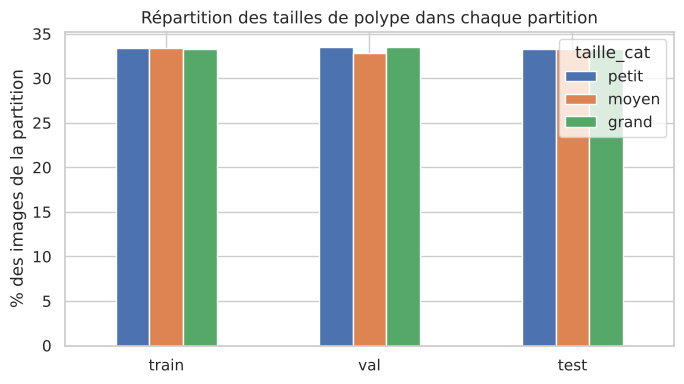

In [15]:
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    A, B = df_clean[df_clean["split"] == a], df_clean[df_clean["split"] == b]
    assert not set(A["id"]) & set(B["id"]), f"Image commune {a}/{b}"
    assert not set(A["hash"]) & set(B["hash"]), f"Doublon exact {a}/{b}"
    assert not set(A["groupe"]) & set(B["groupe"]), f"Quasi-doublon {a}/{b}"
print("✅ Aucune fuite : aucune image, aucun doublon exact et aucun groupe de quasi-doublons partagé.")

prop = (pd.crosstab(df_clean["taille_cat"], df_clean["split"], normalize="columns")
        .reindex(index=TAILLES, columns=ordre) * 100)
fig, ax = plt.subplots(figsize=(7, 4))
prop.T.plot(kind="bar", ax=ax, color=[COULEURS[t] for t in TAILLES])
ax.set_ylabel("% des images de la partition")
ax.set_xlabel("")
ax.set_title("Répartition des tailles de polype dans chaque partition")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/stratification_split.png", dpi=150)
plt.show()

### Sauvegarde de `splits_kvasir.csv`

Même format que `splits.csv` de BUSI, avec deux colonnes en plus : `dataset` et `taille_cat`. Les notebooks suivants pourront ainsi traiter les deux datasets avec le même code. ⚠️ Comme pour BUSI, **ce découpage est fait une seule fois** et partagé sur GitHub.

In [16]:
df_clean["dataset"] = "kvasir"
colonnes = ["dataset", "id", "classe", "taille_cat", "split", "image_path", "mask_paths", "nb_masques",
            "hauteur", "largeur", "ratio_tumeur", "nb_lesions", "hash", "groupe", "taille_groupe"]
df_clean[colonnes].to_csv("splits_kvasir.csv", index=False)
print("splits_kvasir.csv enregistré :", len(df_clean), "images")
display(df_clean["split"].value_counts().reindex(ordre).rename("nb_images").to_frame())

splits_kvasir.csv enregistré : 1000 images


,nb_images
split,
train,701
val,149
test,150


---
## 4. Synthèse

La cellule suivante résume les chiffres clés, à reprendre dans le rapport.

In [17]:
print(f"Images : {len(df)} -> {len(df_clean)} après doublons exacts")
print(f"Polypes par image : 1 pour {(df_clean['nb_lesions'] == 1).sum()} images, plusieurs pour {(df_clean['nb_lesions'] > 1).sum()}")
print(f"Taille des polypes : médiane {df_clean['ratio_tumeur'].median() * 100:.1f} % de l'image "
      f"(de {df_clean['ratio_tumeur'].min() * 100:.1f} à {df_clean['ratio_tumeur'].max() * 100:.1f} %)")
print(f"Quasi-doublons : {avec_copie['groupe'].nunique()} groupes, {len(avec_copie)} images")
print(f"Découpage : {dict(df_clean['split'].value_counts().reindex(ordre))}")

Images : 1000 -> 1000 après doublons exacts
Polypes par image : 1 pour 820 images, plusieurs pour 180
Taille des polypes : médiane 11.4 % de l'image (de 0.5 à 81.2 %)
Quasi-doublons : 4 groupes, 8 images
Découpage : {'train': np.int64(701), 'val': np.int64(149), 'test': np.int64(150)}


| Constat | Décision |
|---|---|
| 1 000 images couleur, une seule classe | Modèles à **3 canaux d'entrée** ; stratification par **taille du polype** |
| Masques JPEG | Binarisation **`> 127`** |
| Tailles d'images très variables | Redimensionnement **256 × 256**, comme BUSI |
| Plusieurs polypes sur une partie des images | Gardés : le masque contient toutes les lésions |
| Cadre commun à toutes les images : la méthode de BUSI crée un faux groupe de 110 images | Empreintes calculées sur le **centre** de l'image, seuils recalibrés (d ≤ 10, c ≥ 0,90) |
| 4 vraies paires de copies (8 images) | Découpage **par groupe** : 701 / 149 / 150, contrôles anti-fuite |
| Aucune image saine | Pas de matrice de confusion **au niveau des images** ; celle **au niveau des pixels** reste valable |